# Whitefly wax segmentation on citrus leaves — pretrained YOLO11s-seg inference (paper reproduction)

**Paper:** *Rail-Guided IoT Imaging System for Leaf-Level Monitoring in Small-Scale Citrus Plots* (SSRG IJECE, Vol. 13, Issue 10, IJECE-V13I10P101, October 2026; DOI 10.14445/23488549/ijece-v13i10p101).
**Author code & data:** https://github.com/Jusepepe/citrus-monitoring (pinned commit `4d608b8c37fe44d11994b8102263ea12106a90b0`).
**Author weights:** `models/best_model.pt` (YOLO11s-seg, 10.1M params).

**Scope (this notebook):** pretrained-inference-only reproduction — load the author's released `best_model.pt`, run the author's documented inference (`conf=0.3`) and test/validation-split evaluation on the repository's own `final_dataset` splits (43 field test images, 74 synthetic validation images), and compare measured metrics with the paper (field test mask mAP50 ≈ 0.209, P ≈ 0.494; synthetic validation mask mAP50 ≈ 0.575) and the README (0.584).

**Not in scope:** training/fine-tuning (100 epochs), the rail/ESP32/Raspberry-Pi hardware pipeline, the web application, and dataset generation. One-example inference is not a verification of the paper's full results.

**Status:** executable partial demonstration (outcome A). All downloads and computation run inside this Colab VM under `/content`.

日本語: 本ノートブックは論文の学習済みモデル `best_model.pt` を著者リポジトリ（固定コミット）から取得し、論文の手順どおり `conf=0.3` で推論・評価（field test 43枚 / 合成validation 74枚）を行い、論文報告値（field test mask mAP50 ≈ 0.209、validation ≈ 0.575）と比較します。学習・ハードウェアパイプラインは対象外です。


## Runtime selection (run all)

Both **CPU** and **GPU (T4)** runtimes faithfully execute this notebook — the device is auto-detected in the next cells. **Recommended: T4 GPU** (evaluation of 117 images finishes in ~1–2 min; CPU takes roughly 5–10 min). Downloads total ≈ 40 MB (weights 20.5 MB + image/label splits). Expected end-to-end time: ≈ 5 min (T4) to ≈ 15 min (CPU).

日本語: CPU でも GPU(T4) でも動作します（自動判定）。推奨は T4 GPU。ダウンロード約40MB、全体所要時間は T4 で約5分、CPU で約15分です。


In [ ]:
%pip install -q "ultralytics>=8.3.0"
import ultralytics
print("ultralytics", ultralytics.__version__)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


ultralytics 8.4.213


### Environment check

Reports Python/torch versions and selects the device (`0` when a CUDA GPU is allocated, otherwise `cpu`). All later inference/evaluation calls pass this device explicitly; nothing falls back silently.

日本語: Python/torch のバージョンと CUDA 利用可否を確認し、以降の推論で使うデバイスを明示的に選択します。


In [ ]:
import platform, torch
print("Python:", platform.python_version())
print("torch:", torch.__version__, "| CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
DEVICE = 0 if torch.cuda.is_available() else "cpu"
print("Selected device:", DEVICE)

Python: 3.13.16
torch: 2.14.1+cu130 | CUDA available: True


GPU: Tesla T4
Selected device: 0


### Data & weights acquisition (pinned author repository)

Per the paper's data availability, the model weights and evaluation images come from the author repository `Jusepepe/citrus-monitoring`. We make a **partial, blob-filtered clone inside Colab** and check out the exact pinned commit `{PIN}` (asserted). Only the needed paths are materialized: `data.yaml`, `models/`, `final_dataset/data/test`, `final_dataset/data/validation`. Nothing is downloaded to any other machine.

日本語: 著者リポジトリを部分クローン（blobなし）し、固定コミットのみを sparse-checkout して必要なファイルだけ取得します。


In [ ]:
REPO_URL = "https://github.com/Jusepepe/citrus-monitoring.git"
PINNED_COMMIT = "4d608b8c37fe44d11994b8102263ea12106a90b0"
!git clone --filter=blob:none --no-checkout {REPO_URL} /content/citrus-monitoring
%cd /content/citrus-monitoring
!git sparse-checkout set data.yaml models final_dataset/data/test final_dataset/data/validation
!git checkout {PINNED_COMMIT}
import subprocess
_head = subprocess.run(["git", "rev-parse", "HEAD"], capture_output=True, text=True, check=True).stdout.strip()
assert _head == PINNED_COMMIT, f"checkout mismatch: {_head}"
print("Checked out pinned commit:", _head[0])

Cloning into '/content/citrus-monitoring'...


remote: Enumerating objects: 25, done.
remote: Total 25 (delta 0), reused 0 (delta 0), pack-reused 25 (from 2)
Receiving objects: 100% (25/25), 63.44 KiB | 1.02 MiB/s, done.


/content/citrus-monitoring


remote: Enumerating objects: 352, done.


remote: Total 352 (delta 0), reused 0 (delta 0), pack-reused 352 (from 1)
Receiving objects: 100% (352/352), 40.48 MiB | 16.71 MiB/s, done.
Resolving deltas: 100% (106/106), done.


Updating files: 100% (437/437), done.
Note: switching to '4d608b8c37fe44d11994b8102263ea12106a90b0'.

You are in 'detached HEAD' state. You can look around, make experimental
changes and commit them, and you can discard any commits you make in this
state without impacting any branches by switching back to a branch.

If you want to create a new branch to retain commits you create, you may
do so (now or later) by using -c with the switch command. Example:

  git switch -c <new-branch-name>

Or undo this operation with:

  git switch -

Turn off this advice by setting config variable advice.detachedHead to false

HEAD is now at 4d608b8 feat: add dataset composition pipeline, training notebooks, experiment dataset, and best YOLOv11s-seg model


Checked out pinned commit: 4


### Download verification

Validates the actual downloaded bytes before any scientific use: exact weight size, its SHA-256, image/label pair counts per split (expected: test 43, validation 74), and that image files decode and label files parse as YOLO segmentation polygons.

日本語: ダウンロードした重みのサイズとSHA-256、各splitの画像/ラベル数（test 43、validation 74）を検証します。


In [ ]:
import glob, hashlib
from pathlib import Path

weights = Path("models/best_model.pt")
assert weights.exists(), "best_model.pt missing"
n_bytes = weights.stat().st_size
sha256 = hashlib.sha256(weights.read_bytes()).hexdigest()
print(f"best_model.pt: {n_bytes} bytes | sha256: {sha256}")
assert n_bytes > 10_000_000, "weights implausibly small (LFS pointer or truncated file?)"

counts = {}
for split in ("test", "validation"):
    imgs = sorted(glob.glob(f"final_dataset/data/{split}/images/*.jpg"))
    lbls = sorted(glob.glob(f"final_dataset/data/{split}/labels/*.txt"))
    counts[split] = (len(imgs), len(lbls))
    print(f"{split}: {len(imgs)} images, {len(lbls)} labels")
assert counts["test"] == (43, 43), counts["test"]
assert counts["validation"] == (74, 74), counts["validation"]

from PIL import Image
for p in imgs[:1] + sorted(glob.glob("final_dataset/data/test/images/*.jpg"))[:1]:
    im = Image.open(p); im.verify()
    print("decoded:", Path(p).name, Image.open(p).size)
lbl = sorted(glob.glob("final_dataset/data/test/labels/*.txt"))[0]
first = open(lbl).readline().split()
print("sample label:", Path(lbl).name, "class:", first[0], "polygon points:", (len(first) - 1) // 2)

best_model.pt: 20520228 bytes | sha256: 10ac7405f6892930a60db30a7e3fbdb75a0512c296a4e3a67706b5b6015415a6
test: 43 images, 43 labels
validation: 74 images, 74 labels
decoded: composite_680.jpg (1024, 1024)
decoded: annotated_bg_797.jpg (1024, 1024)
sample label: annotated_bg_797.txt class: 0 polygon points: 21


### Input preview

Displays the two alphabetically-first field test images (`annotated_bg_797.jpg`, `annotated_bg_798.jpg`) exactly as acquired by the rail platform. These are real orchard images from the author's 43-image field test split — the smallest faithful evaluation set named in the paper (Sec. 3.3.3, Table 1).

日本語: 著者のfield test splitから先頭2枚の実画像をそのまま表示します。


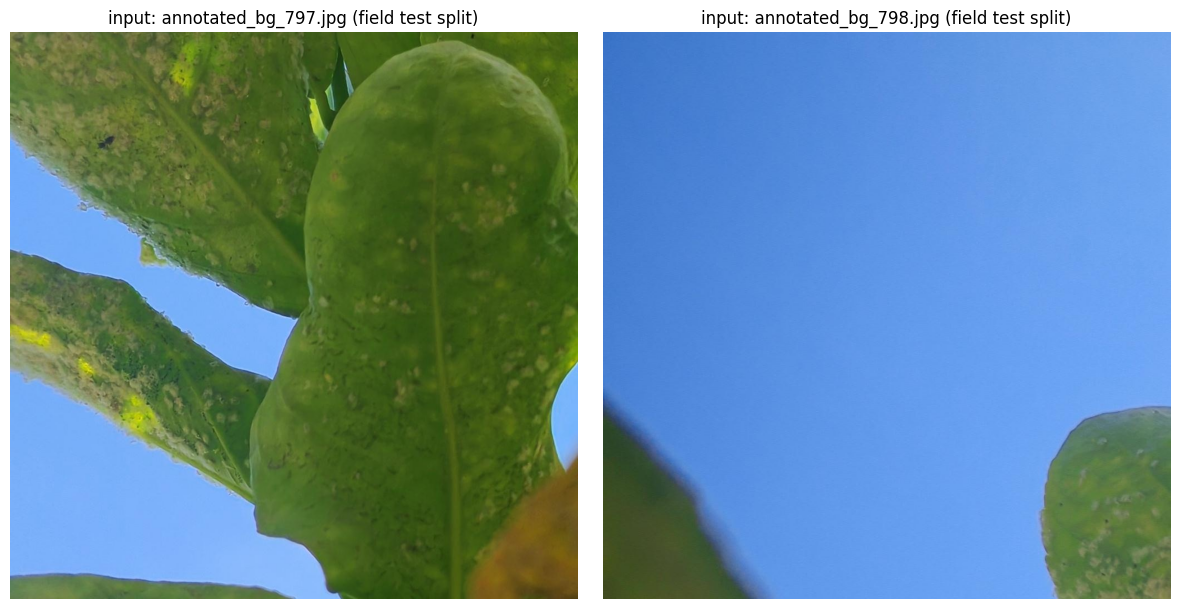

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

test_images = sorted(glob.glob("final_dataset/data/test/images/*.jpg"))
PREVIEW = test_images[:2]
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, p in zip(axes, PREVIEW):
    ax.imshow(Image.open(p))
    ax.set_title(f"input: {Path(p).name} (field test split)")
    ax.axis("off")
plt.tight_layout(); plt.show()

### Ground-truth annotation overlay

The YOLO segmentation labels store class `0` (`wax`) with normalized polygon coordinates. This cell re-renders the **reference annotations** (not model output) filled on the first preview image, so the learner sees what the paper's Label-Studio-verified masks look like.

日本語: YOLOセグメンテーションラベルのポリゴン（正解アノテーション）を画像上に描画します。これはモデル出力ではなく人手正解です。


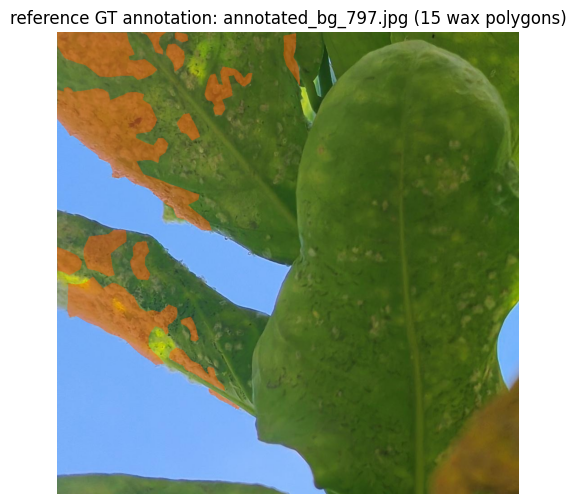

In [ ]:
import cv2
import numpy as np

def draw_gt_polygons(img_path, lbl_path, alpha=0.45):
    img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    overlay = img.copy()
    n = 0
    for line in open(lbl_path):
        parts = line.split()
        if parts[0] == "0" and len(parts) >= 7:  # class + at least 3 points
            pts = (np.array(parts[1:], dtype=float).reshape(-1, 2) * [w, h]).astype(np.int32)
            cv2.fillPoly(overlay, [pts], color=(255, 90, 0))
            n += 1
    return cv2.addWeighted(overlay, alpha, img, 1 - alpha, 0), n

gt_img, n_gt = draw_gt_polygons(PREVIEW[0], PREVIEW[0].replace("/images/", "/labels/").replace(".jpg", ".txt"))
plt.figure(figsize=(6, 6))
plt.imshow(gt_img)
plt.title(f"reference GT annotation: {Path(PREVIEW[0]).name} ({n_gt} wax polygons)")
plt.axis("off"); plt.show()

### Core method: author inference on one field image

Loads the author's released checkpoint exactly as documented in the README ("Load best trained model … `model.predict(..., conf=0.3)`") with `imgsz=640` (paper Sec. 3.3.4) on the selected device. This is the paper's deployed model, not a retrain.

日本語: 著者リリースの `best_model.pt` をREADMEどおり `conf=0.3` で読み込み、field画像1枚に推論します（再学習ではありません）。


In [ ]:
from ultralytics import YOLO

model = YOLO("models/best_model.pt")
result = model.predict(source=PREVIEW[0], conf=0.3, imgsz=640, device=DEVICE, verbose=False)[0]
n_pred = 0 if result.masks is None else len(result.masks)
confs = [] if result.boxes is None else [float(c) for c in result.boxes.conf]
print(f"predicted wax instances: {n_pred} | GT polygons on this image: {n_gt}")
print("confidences:", [round(c, 3) for c in sorted(confs, reverse=True)])

predicted wax instances: 5 | GT polygons on this image: 15
confidences: [0.498, 0.447, 0.365, 0.325, 0.314]


### Prediction overlay and input-vs-GT-vs-prediction comparison

Renders the model's predicted masks (`result.plot()`) and a labeled three-panel figure: original input, reference GT polygons, predicted masks. The predicted panel is **model output**; the GT panel is **reference annotation**.

日本語: 入力画像・正解アノテーション・モデル予測マスクを並べて比較表示します（予測はモデル出力、GTは人手正解）。


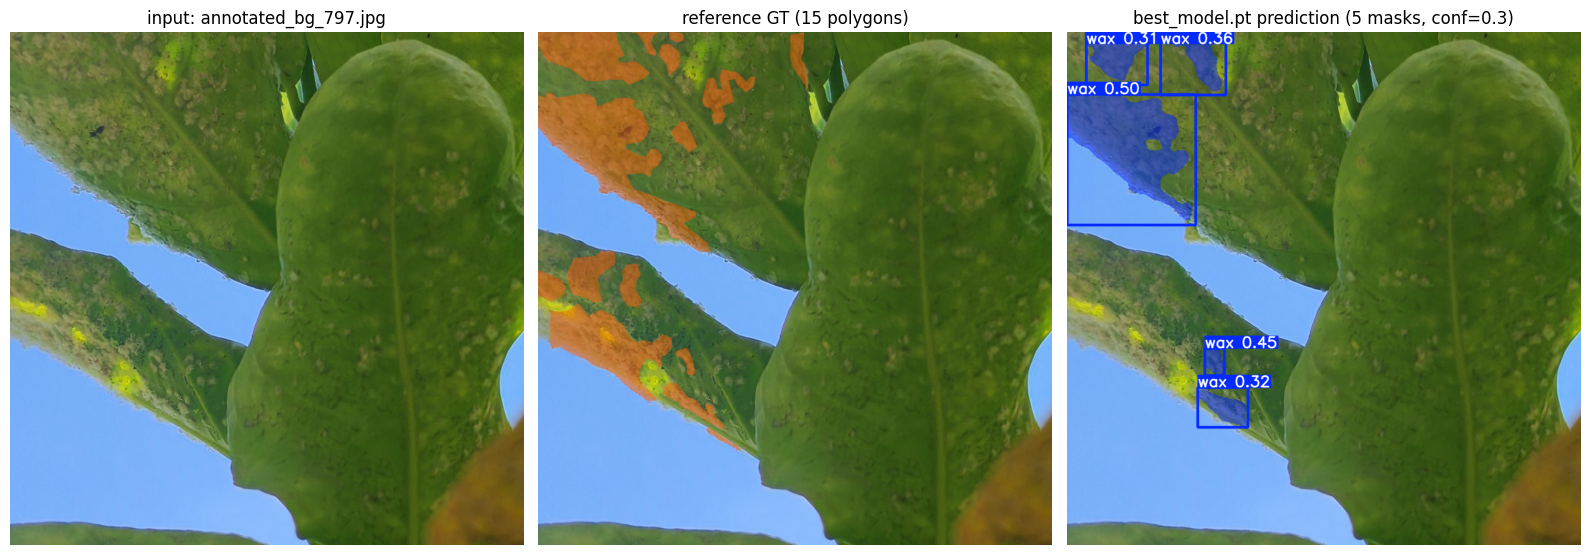

In [ ]:
pred_bgr = result.plot(labels=True, conf=True)  # BGR with mask overlays
pred_rgb = cv2.cvtColor(pred_bgr, cv2.COLOR_BGR2RGB)
input_rgb = cv2.cvtColor(cv2.imread(PREVIEW[0]), cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
axes[0].imshow(input_rgb); axes[0].set_title(f"input: {Path(PREVIEW[0]).name}")
axes[1].imshow(gt_img);     axes[1].set_title(f"reference GT ({n_gt} polygons)")
axes[2].imshow(pred_rgb);   axes[2].set_title(f"best_model.pt prediction ({n_pred} masks, conf=0.3)")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

### Evaluation on the 43-image field test split (paper comparison)

Runs the author's documented test-split validation (`notebooks/task6_training.ipynb`: `yolo task=segment mode=val ... split=test conf=0.3`; here via the equivalent Python API). The paper reports for these 43 real field images: mask mAP50 ≈ **0.209** and precision ≈ **0.494** (abstract/evaluation section). We compare our measured values against those references.

日本語: 著者の手順どおり field test 43枚で評価し、論文報告値（mask mAP50 ≈ 0.209、P ≈ 0.494）と比較します。


In [ ]:
metrics_test = model.val(data="data.yaml", split="test", conf=0.3, imgsz=640, device=DEVICE, verbose=False)
print("=== field test split (43 images, conf=0.3) ===")
print(f"box  P {metrics_test.box.mp:.3f} | R {metrics_test.box.mr:.3f} | mAP50 {metrics_test.box.map50:.3f}")
print(f"mask P {metrics_test.seg.mp:.3f} | R {metrics_test.seg.mr:.3f} | mAP50 {metrics_test.seg.map50:.3f}")

Ultralytics 8.4.213 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)


YOLO11s-seg summary (fused): 114 layers, 10,067,203 parameters, 0 gradients, 32.9 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1670.2±516.4 MB/s, size: 121.0 KB)


val: Scanning /content/citrus-monitoring/final_dataset/data/test/labels... 43 images, 6 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 43/43 1.7Kit/s 0.0s

val: New cache created: /content/citrus-monitoring/final_dataset/data/test/labels.cache


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 33% ━━━━──────── 1/3 3.2s/it 1.0s<6.5s

... (2 outputs left out)

                   all         43        126      0.443      0.278      0.172     0.0777      0.494       0.31      0.209     0.0823


Speed: 3.6ms preprocess, 16.4ms inference, 0.0ms loss, 3.0ms postprocess per image


Results saved to /content/citrus-monitoring/runs/segment/val


=== field test split (43 images, conf=0.3) ===
box  P 0.443 | R 0.278 | mAP50 0.172
mask P 0.494 | R 0.310 | mAP50 0.209


### Evaluation on the 74-image synthetic validation split

The paper reports validation mask mAP50 ≈ **0.575** (abstract) and the repository README states **0.584** for the released model. This uses the default confidence used at training-time validation (no `conf` override), mirroring the author's training-time evaluation.

日本語: 合成validation 74枚で評価し、論文（mask mAP50 ≈ 0.575）とREADME（0.584）の報告値と比較します。


In [ ]:
metrics_val = model.val(data="data.yaml", split="val", imgsz=640, device=DEVICE, verbose=False)
print("=== synthetic validation split (74 images) ===")
print(f"box  P {metrics_val.box.mp:.3f} | R {metrics_val.box.mr:.3f} | mAP50 {metrics_val.box.map50:.3f}")
print(f"mask P {metrics_val.seg.mp:.3f} | R {metrics_val.seg.mr:.3f} | mAP50 {metrics_val.seg.map50:.3f}")

Ultralytics 8.4.213 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)


YOLO11s-seg summary (fused): 114 layers, 10,067,203 parameters, 0 gradients, 32.9 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3250.8±1102.9 MB/s, size: 237.9 KB)


val: Scanning /content/citrus-monitoring/final_dataset/data/validation/labels... 74 images, 14 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 74/74 1.6Kit/s 0.0s

val: New cache created: /content/citrus-monitoring/final_dataset/data/validation/labels.cache


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 20% ━━────────── 1/5 3.9s/it 1.2s<15.5s

... (4 outputs left out)

                   all         74        340      0.563      0.576      0.575      0.336      0.587      0.571      0.572      0.281


Speed: 6.3ms preprocess, 12.8ms inference, 0.0ms loss, 8.8ms postprocess per image


Results saved to /content/citrus-monitoring/runs/segment/val-2


=== synthetic validation split (74 images) ===
box  P 0.563 | R 0.576 | mAP50 0.575
mask P 0.587 | R 0.571 | mAP50 0.572


### Results summary and CSV export

Collected measurements versus the paper/README reference values. Small expected differences come from ultralytics version, hardware and the exact split files; the README/paper themselves differ slightly (0.584 vs 0.575).

日本語: 測定値と論文・READMEの参照値を表にまとめ、CSVに保存します。


In [ ]:
import pandas as pd

rows = [
    ("field test (43)", "mask mAP50", round(float(metrics_test.seg.map50), 3), 0.209, "paper (abstract/eval section)"),
    ("field test (43)", "mask P",     round(float(metrics_test.seg.mp), 3),     0.494, "paper"),
    ("field test (43)", "box mAP50",  round(float(metrics_test.box.map50), 3),  None,  ""),
    ("synthetic val (74)", "mask mAP50", round(float(metrics_val.seg.map50), 3), 0.575, "paper (README states 0.584)"),
    ("synthetic val (74)", "box mAP50",  round(float(metrics_val.box.map50), 3), None,  ""),
]
df = pd.DataFrame(rows, columns=["split", "metric", "measured", "reference", "reference_source"])
print(df.to_string(index=False))
df.to_csv("/content/results_summary.csv", index=False)
print("saved /content/results_summary.csv")

             split     metric  measured  reference              reference_source
   field test (43) mask mAP50     0.209      0.209 paper (abstract/eval section)
   field test (43)     mask P     0.494      0.494                         paper
   field test (43)  box mAP50     0.172        NaN                              
synthetic val (74) mask mAP50     0.572      0.575   paper (README states 0.584)
synthetic val (74)  box mAP50     0.575        NaN                              
saved /content/results_summary.csv


## Interpretation, limitations, references

**What was verified:** the author's released `best_model.pt` runs the documented inference and validation on the repository's own splits; measured field-test and validation metrics are compared with the paper's reported values above.

**Limitations:** a 43-image evaluation reproduces the paper's reported operating point only approximately (ultralytics version, hardware, and the repo's final split files may differ slightly from the paper's Table 1 counts: repo 721/74/43 vs paper 747/88/43/43). Training, the rail/ESP32 acquisition system, and the web viewer are out of scope. The companion repository has no LICENSE file (the README badge claims MIT); all artifacts are fetched from the author's public repository at the pinned commit with attribution.

**References:** paper DOI 10.14445/23488549/ijece-v13i10p101 · author code/data/weights https://github.com/Jusepepe/citrus-monitoring @ `4d608b8c37fe44d11994b8102263ea12106a90b0` · Ultralytics YOLO11 (AGPL-3.0).

日本語: 著者リリースモデルの推論・評価手順を固定コミットから再現し、論文報告値と比較しました。学習・硬件パイプラインは対象外で、リポジトリにはLICENSEファイルがない点に注意してください。
